---
title: "Лекція 8. Data-driven і hybrid моделювання та відтворюване модельно-обчислювальне дослідження"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка

Лекція охоплює:

- *Тему 12. Data-driven та hybrid modelling складних систем* -- 1 год;
- *Тему 13. Відтворюване моделювання та модель як інструмент отримання нового знання* -- 1 год.

Це завершальна лекція курсу. Її наскрізна логіка:

$$
\text{knowledge-driven model}
+
\text{data}
\rightarrow
\text{hybrid/data-driven model}
\rightarrow
\text{reproducible experiment}
\rightarrow
\text{traceable evidence}
\rightarrow
\text{scientific inference}.
$$

Ключова теза всього курсу:

$$
\boxed{
\text{model}
\neq
\text{reality},
\qquad
\text{model output}
\neq
\text{scientific knowledge}
}
$$

Модель стає інструментом отримання нового знання лише через обґрунтований, перевірюваний і відтворюваний inference process.
:::

# Вступ

У попередніх темах ми послідовно пройшли:

$$
\text{formalization}
\rightarrow
\text{dynamics}
\rightarrow
\text{networks}
\rightarrow
\text{identification}
\rightarrow
V\&V
\rightarrow
SA/UQ
\rightarrow
\text{experimental design}.
$$

Тепер потрібно відповісти на два завершальні питання.

1. Як поєднати mathematical structure і data?
2. Як перетворити весь computational workflow на research artifact, з якого можна відтворити scientific claim?

# Тема 12. Data-driven та hybrid modelling складних систем

## 1. Три джерела інформації про систему

Для побудови model ми можемо використовувати:

1. *domain knowledge*;
2. *observational / experimental data*;
3. *computational evidence*.

Knowledge-driven model спирається передусім на assumptions про mechanisms.

Data-driven model спирається передусім на statistical structure data.

Hybrid model поєднує обидва джерела [@bruntonKutz2022].

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Domain<br/>knowledge") --> C("Model")
 B("Data") --> C
 C --> D("Prediction /<br/>explanation")
 D --> E("Evidence")
```

## 2. Knowledge-driven model

Нехай system state:

$$
\mathbf x(t)\in\mathbb R^n.
$$

Knowledge-driven model може мати вигляд

$$
\frac{d\mathbf x}{dt}
=
\mathbf f
(
\mathbf x,
\mathbf u,
\boldsymbol\theta
).
$$

Structure $\mathbf f$ задається на основі:

- laws;
- mechanisms;
- balance relations;
- interaction rules;
- expert assumptions.

Data можуть використовуватися для identification parameters:

$$
\hat{\boldsymbol\theta}
=
\arg\min_{\boldsymbol\theta}
J
(
\boldsymbol\theta;D
).
$$

Отже, наявність calibration data ще не робить model data-driven.

## 3. Data-driven model

У data-driven formulation mapping отримується переважно з observations:

$$
\hat{\mathbf y}
=
g
(
\mathbf z;\boldsymbol\phi
).
$$

Parameters $\boldsymbol\phi$ визначаються через learning:

$$
\hat{\boldsymbol\phi}
=
\arg\min_{\boldsymbol\phi}
\mathcal L
(
D;
\boldsymbol\phi
).
$$

Examples:

- regression;
- neural networks;
- Gaussian processes;
- tree ensembles;
- state-space identification;
- dynamic mode decomposition;
- sparse equation discovery.

Але data-driven model також містить assumptions:

- feature representation;
- model class;
- loss;
- regularization;
- training distribution.

Тому:

$$
\text{data-driven}
\neq
\text{assumption-free}.
$$

## 4. Hybrid model як клас моделей

*Гібридна модель (hybrid model)* поєднує knowledge-driven і learned components.

Загально:

$$
\hat y
=
H
(
M(\mathbf x;\theta),
g(\mathbf z;\phi)
).
$$

Але термін *hybrid* сам по собі майже нічого не говорить.

Потрібно вказати:

1. де розташований learned component;
2. що він замінює;
3. що він коригує;
4. які constraints зберігаються;
5. як він навчається;
6. у якому domain перевірений.

## 5. Gray-box modelling

Між white-box і black-box існує широкий клас *сірих моделей (gray-box models)*.

Схематично:

$$
\text{known structure}
+
\text{unknown component}.
$$

Наприклад:

$$
\frac{dx}{dt}
=
f_{known}(x,u)
+
g_{unknown}(x,u).
$$

Якщо $g_{unknown}$ апроксимується data-driven model:

$$
\hat g
=
g(x,u;\phi),
$$

отримуємо один із типових hybrid architectures.

Gray-box model -- це не компроміс «50% physics + 50% ML». Це model, де відомі та невідомі компоненти розділені концептуально.

## 6. Residual correction

Архітектура, використана в ЛР7:

$$
\hat y_H
=
\hat y_M
+
\hat\delta.
$$

Data-driven component навчається на residual:

$$
\delta_i
=
y_i
-
\hat y_{M,i}.
$$

Це може бути корисно, якщо mechanistic model:

- правильно задає dominant trend;
- має systematic discrepancy;
- зберігає meaningful extrapolation structure.

Але learned residual може компенсувати не лише missing mechanism, а й:

- parameter error;
- measurement bias;
- preprocessing artifact;
- numerical error.

Тому:

$$
\text{successful correction}
\not\Rightarrow
\text{correct mechanism}.
$$

## 7. Learned closure

У multiscale model часто відома macro-structure, але невідомий closure term.

Наприклад:

$$
\frac{dX}{dt}
=
F(X)
+
C(X).
$$

$C(X)$ представляє unresolved processes.

Замість ad hoc closure:

$$
C(X)
\approx
g(X;\phi).
$$

Це принципово інша hybridization, ніж output residual correction:

$$
\text{correction of output}
\neq
\text{learning internal mechanism}.
$$

Розташування learned component впливає на interpretability, stability і validity.

## 8. Surrogate model

*Сурогатна модель (surrogate model)* апроксимує expensive computational model:

$$
M_{high}(\mathbf x)
\approx
S(\mathbf x;\phi).
$$

Мета -- не обов'язково краще описати reality.

Мета -- дешевше апроксимувати

$$
M_{high}.
$$

Surrogate корисний для:

- global sensitivity analysis;
- optimization;
- uncertainty propagation;
- large parameter sweeps;
- real-time computation.

Отже:

$$
\text{surrogate validity}
\text{ визначається відносно }
M_{high}
\text{ і intended use}.
$$

## 9. Простий surrogate example

Нехай expensive simulator задає

$$
y
=
\sin(x)+0.1x^2.
$$

Навчимо polynomial surrogate лише як ілюстрацію approximation.

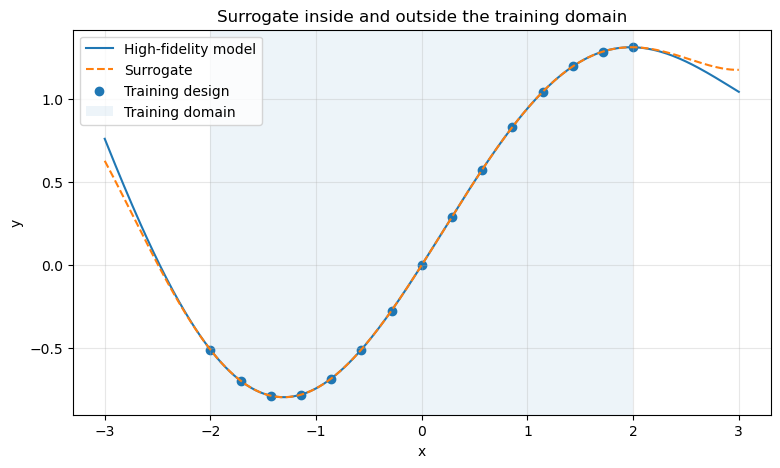

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

def expensive_model(x):
    x = np.asarray(x)
    return np.sin(x) + 0.1 * x**2

x_train = np.linspace(
    -2.0,
    2.0,
    15
)

y_train = expensive_model(
    x_train
)

surrogate = make_pipeline(
    PolynomialFeatures(
        degree=5,
        include_bias=False
    ),
    Ridge(alpha=1e-4)
)

surrogate.fit(
    x_train.reshape(-1, 1),
    y_train
)

x_dense = np.linspace(
    -3.0,
    3.0,
    300
)

y_true = expensive_model(
    x_dense
)

y_sur = surrogate.predict(
    x_dense.reshape(-1, 1)
)

plt.figure(figsize=(9, 5))
plt.plot(
    x_dense,
    y_true,
    label="High-fidelity model"
)
plt.plot(
    x_dense,
    y_sur,
    linestyle="--",
    label="Surrogate"
)
plt.scatter(
    x_train,
    y_train,
    label="Training design"
)
plt.axvspan(
    -2.0,
    2.0,
    alpha=0.08,
    label="Training domain"
)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Surrogate inside and outside the training domain")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Графік демонструє принципову річ:

$$
\text{surrogate accuracy inside }D_{train}
\not\Rightarrow
\text{accuracy outside }D_{train}.
$$

Тому surrogate має власний domain of validity.

## 10. Reduced-order model

*Модель зниженого порядку (Reduced-Order Model, ROM)* зменшує dimensionality system.

Нехай:

$$
\mathbf x(t)\in\mathbb R^n,
\qquad
n\gg1.
$$

Шукаємо low-dimensional representation:

$$
\mathbf x(t)
\approx
\mathbf V\mathbf a(t),
$$

де

$$
\mathbf a(t)\in\mathbb R^r,
\qquad
r\ll n.
$$

Тоді замість full model досліджуємо dynamics latent coordinates:

$$
\frac{d\mathbf a}{dt}
=
\mathbf f_r(\mathbf a).
$$

ROM може бути:

- projection-based;
- data-driven;
- hybrid.

Тому:

$$
\text{ROM}
\neq
\text{synonym of surrogate}.
$$

## 11. Surrogate vs Reduced-Order Model

| Ознака | Surrogate | ROM |
|---|---|---|
| Що апроксимує | input-output mapping / simulator | high-dimensional state dynamics |
| Основна мета | зменшити cost evaluation | зменшити dimensionality |
| Internal state | може бути відсутній | зазвичай reduced state |
| Data-driven? | часто | може бути, але не обов'язково |
| Mechanistic structure | не обов'язкова | може частково зберігатися |

Обидва підходи потребують власної verification/validation relative to intended use.

## 12. ML-assisted modelling

Machine learning може не бути самою model.

Воно може підтримувати окремий етап:

$$
\text{model workflow}
=
\text{mechanistic core}
+
\text{ML-assisted operation}.
$$

Наприклад:

- parameter estimation;
- closure learning;
- anomaly detection;
- adaptive meshing;
- regime classification;
- emulator;
- error correction;
- feature extraction.

Тому термін *ML-assisted modelling* часто точніший за загальне *hybrid modelling*.

## 13. Data assimilation

*Асиміляція даних (data assimilation)* поєднує model forecast і нові observations для updating state.

Нехай forecast:

$$
\mathbf x_k^f.
$$

Observation:

$$
\mathbf y_k
=
H\mathbf x_k
+
\boldsymbol\varepsilon_k.
$$

Update у лінійному вигляді:

$$
\mathbf x_k^a
=
\mathbf x_k^f
+
K_k
\left(
\mathbf y_k
-
H\mathbf x_k^f
\right),
$$

де $K_k$ -- gain matrix.

Тут data не просто один раз калібрують parameters.

Вони послідовно змінюють estimate state.

## 14. Model updating

Поняття *model updating* ширше за data assimilation.

Data можуть оновлювати:

- state;
- parameters;
- boundary conditions;
- model discrepancy;
- structure;
- uncertainty distributions.

Схематично:

$$
M^{(k)}
+
D_{new}
\rightarrow
M^{(k+1)}.
$$

Але кожне updating змінює research artifact.

Тому після updating потрібно фіксувати нову model version.

## 15. Порівняння основних архітектур

| Архітектура | Що дає knowledge | Що дають data | Основний ризик |
|---|---|---|---|
| Mechanistic | structure + equations | parameters / validation | model-form error |
| Data-driven | weak prior / model class | mapping | distribution shift |
| Residual hybrid | baseline structure | discrepancy correction | masking wrong mechanism |
| Learned closure | macro structure | unresolved term | instability / nonphysical behavior |
| Surrogate | high-fidelity simulator | approximation | domain extrapolation |
| ROM | reduced representation | basis/dynamics | lost modes |
| Data assimilation | dynamic forecast | state correction | wrong uncertainty model |

Немає універсально «найкращої» архітектури.

Правильне питання:

> Яка architecture відповідає Research Question, available evidence та intended use?

## 16. Вибір architecture як наукове рішення

Вибір model architecture має бути аргументований через:

$$
\text{RQ}
+
\text{available knowledge}
+
\text{data}
+
\text{computational budget}
+
\text{required inference}.
$$

Наприклад:

- якщо потрібне causal/mechanistic explanation -- black-box predictor може бути недостатнім;
- якщо high-fidelity simulator занадто expensive -- surrogate може бути виправданим;
- якщо частина mechanism невідома -- learned closure може бути природним;
- якщо observations надходять online -- потрібне model updating / data assimilation.

Architecture -- це частина methodology, а не лише implementation choice.

## 17. Нові uncertainty sources у hybrid model

Hybridization не лише зменшує error.

Вона додає uncertainty:

- training-data uncertainty;
- model-class uncertainty;
- hyperparameter uncertainty;
- optimization uncertainty;
- distribution shift;
- learned-component extrapolation;
- interaction між mechanistic та learned components.

Тому:

$$
U_{hybrid}
\neq
U_{mechanistic}
-
\text{``ML correction''}.
$$

Hybrid model потребує нового credibility argument.

## 18. Hybrid model і V&V

Для hybrid model потрібно перевіряти щонайменше три рівні:

### 1. Mechanistic component

$$
M(\mathbf x;\theta)
$$

### 2. Learned component

$$
g(\mathbf z;\phi)
$$

### 3. Integrated system

$$
H(M,g).
$$

Навіть якщо кожний component окремо має добрі metrics, integrated behavior може мати:

- instability;
- constraint violation;
- feedback amplification;
- unexpected extrapolation.

Отже:

$$
V\&V(H)
\neq
V\&V(M)+V\&V(g).
$$

## 19. Перехід до Теми 13

До цього моменту ми навчилися:

- будувати model;
- калібрувати;
- перевіряти;
- оцінювати uncertainty;
- ставити computational experiment;
- інтегрувати data-driven components.

Але scientific result повинен бути *відтворюваним і простежуваним*.

Питання:

> Чи може інший дослідник відновити, з якої саме model version, data version, parameter set і experiment configuration виник конкретний figure, table або scientific claim?

# Тема 13. Відтворюване моделювання та модель як інструмент отримання нового знання

## 20. Reproducibility як властивість дослідження

*Відтворюваність (reproducibility)* у computational research означає можливість отримати узгоджений результат, використовуючи задокументовані computational artifacts і procedure.

Термінологія reproducibility / replicability у різних communities може відрізнятися, тому важливо явно визначати operational meaning [@antunesHill2024].

У межах курсу використовуємо практичне правило:

> Research result має бути пов'язаний із достатнім набором artifacts, щоб computational path до нього можна було повторити та перевірити.

## 21. Research artifact

Модельно-обчислювальне дослідження -- це не один `.ipynb`.

Research artifact:

$$
\mathcal A
=
\{
M,D,\Theta,C,E,R,P
\},
$$

де:

- $M$ -- model;
- $D$ -- data;
- $\Theta$ -- parameters;
- $C$ -- code/configuration;
- $E$ -- computational environment;
- $R$ -- results;
- $P$ -- provenance.

Схематично:

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart TD
 A("Research<br/>Question") --> B("Model<br/>version")
 A --> C("Data<br/>version")
 B --> D("Experiment<br/>configuration")
 C --> D
 D --> E("Code +<br/>environment")
 E --> F("Results")
 F --> G("Figures +<br/>tables")
 G --> H("Scientific<br/>claim")
```

## 22. Provenance

*Походження даних і результатів (provenance)* відповідає на питання:

> Звідки взявся цей result?

Для figure $F_3$ бажано мати trace:

$$
F_3
\leftarrow
R_{17}
\leftarrow
E_{04}
\leftarrow
M_{v2.1}
+
D_{v3}
+
\Theta_{cal5}.
$$

Тоді зміна будь-якого component може бути простежена.

Без provenance researcher бачить output, але не може надійно відновити computational history.

## 23. Traceability matrix

Для складного PhD-проєкту корисна *матриця простежуваності (traceability matrix)*.

| Claim | QoI | Experiment | Model | Data | Figure/Table |
|---|---|---|---|---|---|
| $C_1$ | $Q_1$ | E01 | M2.1 | D3 | Fig. 4 |
| $C_2$ | $Q_2$ | E03 | M2.1 | D4 | Table 2 |

Це не бюрократія.

Вона захищає від ситуації:

> «Який саме запуск породив цей графік?»

## 24. Versioning

Versioning потрібен не лише code.

Версіонувати доцільно:

- model specification;
- source code;
- data;
- parameter sets;
- experiment configuration;
- environment;
- reports.

Наприклад:

$$
M_{1.2}
+
D_{3.0}
+
\Theta_{5}
+
E_{7}
\rightarrow
R_{7}.
$$

Якщо model structure змінилася, старі validation results не можна автоматично переносити на нову version.

## 25. Configuration as data

Погана практика:

```python
beta = 0.2
runs = 200
seed = 42
```

розкидані в різних code cells.

Краще розглядати configuration як окремий artifact:

```yaml
model_version: "2.1"
beta: 0.2
runs: 200
seed: 42
horizon: 50
```

Тоді experiment можна ідентифікувати через configuration, а не через пам'ять дослідника.

## 26. Environment

Однаковий code не гарантує однаковий result, якщо змінюються:

- Python version;
- package versions;
- numerical libraries;
- solver implementation;
- hardware;
- random-number generator.

Мінімальна environment metadata:

$$
\{
\text{Python},
\text{NumPy},
\text{SciPy},
\text{scikit-learn},
\ldots
\}.
$$

Для більш строгого workflow використовують environment files або containers.

In [4]:
import sys
import numpy
import scipy
import sklearn

environment = {
    "python": sys.version.split()[0],
    "numpy": numpy.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__
}

pd.Series(
    environment,
    name="version"
)

python          3.11.14
numpy             2.4.2
scipy            1.17.0
scikit-learn      1.8.0
Name: version, dtype: str

## 27. Randomness як частина provenance

Для stochastic experiment недостатньо написати:

> seed = 42.

Потрібно знати:

- generator;
- seed policy;
- чи seed reused;
- чи застосовано CRN;
- скільки replications;
- як агрегувалися realizations.

Randomness -- частина experimental design.

Тому:

$$
\text{random seed}
\subset
\text{experiment metadata}.
$$

## 28. Reproducible pipeline

Ідеальний workflow можна подати як directed acyclic graph:

$$
D_{raw}
\rightarrow
D_{clean}
\rightarrow
\Theta
\rightarrow
M
\rightarrow
E
\rightarrow
R
\rightarrow
F.
$$

Якщо змінюється $D_{raw}$, downstream artifacts повинні бути regenerated.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Raw<br/>data") --> B("Processed<br/>data")
 B --> C("Calibration")
 C --> D("Model")
 D --> E("Experiment")
 E --> F("Results")
 F --> G("Figures /<br/>tables")
 G --> H("Report")
```

## 29. Notebook: переваги та обмеження

Jupyter/Quarto notebook добре поєднує:

- narrative;
- equations;
- code;
- figures;
- results;
- citations.

Але notebook може приховувати проблеми:

- execution out of order;
- hidden state;
- manual edits;
- missing external files;
- environment dependence.

Тому сильна перевірка:

> Чи виконується notebook *Restart Kernel → Run All*?

Якщо ні, computational narrative не є self-consistent.

## 30. Reproducibility levels

Практично можна виділити кілька рівнів.

### Level 0 -- result only

Є figure/table, але немає computational path.

### Level 1 -- code available

Code є, але data/config/environment неповні.

### Level 2 -- executable workflow

Є code + data + configuration + environment.

### Level 3 -- traceable research artifact

Додатково:

- versioning;
- provenance;
- experiment protocol;
- links claim → evidence;
- automated regeneration.

Для PhD-дослідження бажано рухатися до Level 3.

## 31. Model output не є scientific claim

Припустімо model дала:

$$
Q_A=0.74,
\qquad
Q_B=0.61.
$$

Output:

$$
Q_A-Q_B=0.13.
$$

Але scientific claim потребує відповіді:

- що таке $A$ і $B$?
- який design?
- яка uncertainty?
- чи effect robust?
- чи model validated у цьому regime?
- чи є competing explanation?
- яка population/system scope?

Отже:

$$
\text{number}
\not\Rightarrow
\text{knowledge}.
$$

## 32. Evidence chain

Scientific claim $C$ повинен мати ланцюг:

$$
C
\leftarrow
I
\leftarrow
R
\leftarrow
E
\leftarrow
M,D,\Theta.
$$

де:

- $C$ -- claim;
- $I$ -- inference rule;
- $R$ -- result;
- $E$ -- experiment;
- $M$ -- model;
- $D$ -- data;
- $\Theta$ -- parameters.

Якщо будь-яка ланка непрозора, claim слабшає.

## 33. Три рівні тверджень

Корисно розрізняти:

### Рівень 1. Computational statement

> У model $M$ за conditions $X$ отримано $Y$.

### Рівень 2. Model-based inference

> У validated domain model evidence підтримує relationship $R$.

### Рівень 3. Claim about real system

> У real system діє mechanism $R$.

Перехід

$$
1\rightarrow2
$$

потребує credibility evidence.

Перехід

$$
2\rightarrow3
$$

потребує додаткового empirical/theoretical justification.

Ці рівні не можна змішувати.

## 34. Negative result як науковий результат

Computational experiment може показати:

- effect нестабільний;
- hypotheses indistinguishable;
- uncertainty занадто велика;
- data недостатні;
- model classes дають суперечливі predictions.

Це не «невдале моделювання».

Це може бути нове знання:

$$
\text{current evidence is insufficient to distinguish }H_1,H_2.
$$

Таке твердження часто методологічно сильніше за штучно категоричний висновок.

## 35. Model as epistemic instrument

Математична model виконує щонайменше чотири ролі:

1. *representation* -- формалізує assumptions;
2. *computation* -- породжує consequences assumptions;
3. *experiment* -- дозволяє досліджувати counterfactual/scenario regimes;
4. *inference* -- пов'язує evidence із scientific claims.

Тому model -- не лише formula або program.

У PhD-дослідженні model є *епістемічним інструментом (epistemic instrument)*.

## 36. Межі знання, отриманого з моделі

Scientific inference обмежують:

$$
\mathcal B
=
\{
D_{val},
\mathcal D_{exp},
U,
A,
UQ
\},
$$

де:

- $D_{val}$ -- validation evidence;
- $\mathcal D_{exp}$ -- experimental design space;
- $U$ -- intended use;
- $A$ -- assumptions;
- $UQ$ -- quantified/unquantified uncertainties.

Тому правильний conclusion має форму:

> За assumptions $A$, у domain $D$, для intended use $U$, evidence $E$ підтримує claim $C$ із limitations $L$.

## 37. Reproducible Research Artifact

Фінальний artifact курсу можна представити як:

$$
\mathcal R
=
\{
RQ,
M,
D,
\Theta,
V\&V,
SA,
UQ,
E,
C,
P
\}.
$$

де:

- $RQ$ -- Research Question;
- $M$ -- model specification;
- $D$ -- data;
- $\Theta$ -- parameters;
- $V\&V$ -- credibility evidence;
- $SA$ -- sensitivity;
- $UQ$ -- uncertainty;
- $E$ -- experimental protocol/results;
- $C$ -- bounded claims;
- $P$ -- provenance/reproducibility metadata.

Саме такий artifact має стати результатом ЛР8.

## 38. Артефактна вертикаль курсу

У лабораторних роботах ми послідовно формували:

$$
\text{v0.1 Model Specification}
$$

$$
\downarrow
$$

$$
\text{v0.2 Dynamic Model Specification}
$$

$$
\downarrow
$$

$$
\text{v0.3 Network Model Specification}
$$

$$
\downarrow
$$

$$
\text{v0.4 Network Dynamics Specification}
$$

$$
\downarrow
$$

$$
\text{v0.5 Calibration Specification}
$$

$$
\downarrow
$$

$$
\text{v0.6 Model Credibility Report}
$$

$$
\downarrow
$$

$$
\text{v0.7 Hybrid Experiment Specification}
$$

$$
\downarrow
$$

$$
\boxed{
\text{v1.0 Reproducible Research Artifact}
}
$$

Це не набір незалежних лабораторних.

Це поступове перетворення початкової conceptual model на research-grade computational artifact.

## 39. Повна логіка дисципліни

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Complex<br/>system") --> B("Formalization")
 B --> C("Mathematical /<br/>computational model")
 C --> D("Dynamics +<br/>structure")
 D --> E("Identification +<br/>calibration")
 E --> F("V&V")
 F --> G("Sensitivity +<br/>UQ")
 G --> H("Computational<br/>experiment")
 H --> I("Hybrid /<br/>data-driven model")
 I --> J("Reproducible<br/>artifact")
 J --> K("Scientific<br/>inference")
```

Ця схема і є методологічним ядром курсу.

# 40. Підготовка до ЛР8

Фінальна лабораторна робота має нормативну назву:

*«Лабораторна робота 8. Відтворюване модельно-обчислювальне дослідження складної системи».*

Її мета -- не додати ще один algorithm.

Потрібно інтегрувати попередні artifacts у єдине дослідження:

$$
RQ
\rightarrow
M
\rightarrow
D
\rightarrow
\Theta
\rightarrow
V\&V
\rightarrow
SA/UQ
\rightarrow
E
\rightarrow
C
\rightarrow
\mathcal R.
$$

Основне питання ЛР8:

> Чи можна від Research Question пройти до scientific claim так, щоб кожний computational крок був відтворюваним, а кожний claim -- простежуваним до evidence?

# Контрольні запитання

1. Чим knowledge-driven model відрізняється від data-driven model?
2. Чому calibrated mechanistic model не стає автоматично data-driven?
3. Чому data-driven model не є assumption-free?
4. Що таке hybrid model?
5. Що потрібно вказати, називаючи model hybrid?
6. Що таке gray-box model?
7. Що таке residual correction?
8. Чому successful residual correction не доводить правильність mechanism?
9. Що таке learned closure?
10. Чим learned closure відрізняється від output correction?
11. Що таке surrogate model?
12. Відносно чого оцінюється surrogate fidelity?
13. Що таке Reduced-Order Model?
14. Чим ROM відрізняється від surrogate?
15. Що означає ML-assisted modelling?
16. Що таке data assimilation?
17. Чим model updating ширше за data assimilation?
18. Які нові uncertainty sources додає hybridization?
19. Чому V&V integrated hybrid model не зводиться до окремої перевірки components?
20. Що таке computational reproducibility?
21. Що входить до research artifact?
22. Що таке provenance?
23. Для чого потрібна traceability matrix?
24. Що потрібно versionувати у computational research?
25. Чому configuration слід розглядати як data/artifact?
26. Чому environment є частиною reproducibility?
27. Чому random seed недостатній без seed policy?
28. Що таке reproducible pipeline?
29. Які ризики hidden state має notebook?
30. Що перевіряє `Restart Kernel → Run All`?
31. Які рівні reproducibility можна виділити?
32. Чому model output не є scientific claim?
33. Що таке evidence chain?
34. Чим computational statement відрізняється від claim about real system?
35. Чому negative result може бути науковим результатом?
36. У якому сенсі model є epistemic instrument?
37. Що обмежує model-based scientific inference?
38. Що має містити Reproducible Research Artifact?
39. Як пов'язані artifacts ЛР1--ЛР8?
40. Яка загальна методологічна логіка дисципліни?

# Висновки

1. Knowledge-driven, data-driven та hybrid models використовують різні способи внесення knowledge і data у model structure.
2. Data-driven modelling не є assumption-free.
3. Hybrid model потрібно описувати через конкретну architecture і роль learned component.
4. Gray-box modelling формалізує поділ між known та unknown components.
5. Residual correction виправляє discrepancy, але не доводить правильність mechanism.
6. Learned closure інтегрує data-driven component усередину dynamics.
7. Surrogate model апроксимує expensive simulator, а не обов'язково reality.
8. Reduced-order model зменшує dimensionality system і не є синонімом surrogate.
9. ML може підтримувати окремі етапи mechanistic modelling без перетворення всієї model на black box.
10. Data assimilation і model updating дозволяють інтегрувати нові observations у model state/parameters.
11. Hybridization додає нові uncertainty sources і потребує нового credibility argument.
12. Reproducibility стосується не лише code, а всього research workflow.
13. Research artifact включає model, data, parameters, code, configuration, environment, results і provenance.
14. Versioning і traceability пов'язують конкретний scientific claim із конкретною model/data/experiment version.
15. Notebook є корисним research medium, але hidden state може руйнувати reproducibility.
16. Scientific claim не випливає автоматично з model output.
17. Evidence chain пов'язує claim із inference rule, result, experiment, model і data.
18. Model-based inference має бути обмежене domain of validity, intended use, assumptions та uncertainty.
19. Negative або inconclusive computational result також може бути науково значущим.
20. Фінальний результат курсу -- не набір моделей, а відтворюваний model-based research workflow для отримання обґрунтованого нового знання.

# Джерела та корисні ресурси

Використовується спільна накопичувальна бібліографічна база курсу `mmss-references.bib`.

- [Jupyter](https://jupyter.org/)
- [Quarto](https://quarto.org/)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [SciPy documentation](https://docs.scipy.org/doc/scipy/)
- [scikit-learn documentation](https://scikit-learn.org/stable/)
- [Git documentation](https://git-scm.com/doc)
- [NetworkX documentation](https://networkx.org/documentation/stable/)
- [SALib documentation](https://salib.readthedocs.io/)

# References